# spectral-trust quickstart

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vcnoel/spectral-trust/blob/main/notebooks/01_quickstart.ipynb)

spectral-trust reads each attention head of a transformer as a weighted graph
over the tokens and measures it: the Laplacian spectrum of every head, and the
frequency content of the residual stream on those graphs, from one forward
pass. This notebook loads GPT-2 small, measures three sentences in one call,
plots the Fiedler value and the high-frequency energy ratio (HFER) of every
layer, shows the built-in views, and walks through the `SpectralCache` that
holds the results.

**Runtime:** CPU is enough (Colab: *Runtime > Change runtime type > CPU*).
The first run downloads GPT-2 small (about 550 MB); after that the notebook
runs in under a minute.

In [1]:
%pip install -q "spectral-trust[viz]==0.5.0"

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
os.environ.setdefault("TQDM_DISABLE", "1")          # no progress bars in the outputs

import numpy as np
import torch
import transformers

import spectral_trust as st

transformers.logging.set_verbosity_error()
transformers.utils.logging.disable_progress_bar()
print("spectral-trust", st.__version__, "| torch", torch.__version__,
      "| transformers", transformers.__version__)

spectral-trust 0.5.0 | torch 2.11.0+cu128 | transformers 5.2.0


## Load a model and run it

`SpectralModel.from_pretrained` loads a Hugging Face causal LM with eager
attention, the implementation that returns attention weights.
`run_with_spectra` runs it once on a list of texts and measures every layer
and every head.

In [3]:
model = st.SpectralModel.from_pretrained("gpt2")
texts = [
    "The cat sat on the mat because it was warm.",
    "The capital of France is Paris.",
    "When Mary and John went to the store, John gave a drink to Mary.",
]
cache = model.run_with_spectra(texts)
print(model)
print(cache)
print(cache.tokens[0])

SpectralModel('gpt2', 12 layers, 12 heads, normalization='sym')
SpectralCache('gpt2', 3 texts, 7-16 tokens, layers 0-11, 12 heads, metrics: attn=5, resid=4, graph=10)
['The', ' cat', ' sat', ' on', ' the', ' mat', ' because', ' it', ' was', ' warm', '.']


## Read the cache

Keys follow TransformerLens' naming, `blocks.{layer}.{namespace}.{metric}`:

- `attn.*`: five attention-only metrics of each head's graph;
- `resid.*`: four metrics of the residual stream on each head's graph;
- `graph.*`: every metric of the head-averaged graph of the layer.

For a batch, values gain a leading text dimension, and `cache[i]` is the cache
of text `i`.

In [4]:
fiedler = cache["blocks.6.attn.fiedler_value"]      # [texts, heads]
print(fiedler.shape)
print(fiedler.round(3))
print(cache["blocks.6.graph.hfer"])                 # [texts]: the head-averaged graph

cat = cache[0]                                      # text 0 as a single-text cache
print(cat["attn.fiedler_value", 6].round(3))        # the same as cat["blocks.6.attn.fiedler_value"]
print({k: cat.families[k] for k in ("attn.fiedler_value", "resid.hfer", "graph.hfer")})
cat.layer(6).head(3)                                # every measurement of one head

(3, 12)
[[0.709 0.79  0.858 0.74  0.552 0.719 0.771 0.621 0.559 0.971 0.769 0.389]
 [0.773 0.747 0.822 0.771 0.773 0.805 0.889 0.737 0.621 0.986 0.916 0.77 ]
 [0.325 0.426 0.866 0.685 0.571 0.659 0.616 0.56  0.431 0.59  0.859 0.487]]
[0.51346767 0.46613187 0.54258823]
[0.709 0.79  0.858 0.74  0.552 0.719 0.771 0.621 0.559 0.971 0.769 0.389]
{'attn.fiedler_value': 'attention', 'resid.hfer': 'hybrid', 'graph.hfer': 'hybrid'}


HeadSpectra(layer 6, head 3)
  attn.fiedler_value           0.7400
  attn.connectivity_ratio      0.5109
  attn.spectral_entropy_norm   0.9542
  attn.hfer                    0.6523
  attn.spectral_radius         1.4485
  resid.energy                 6780052.0000
  resid.smoothness_index       0.7238
  resid.spectral_entropy       0.9728
  resid.hfer                   0.4551

Every metric is tagged with its family: *attention* metrics read the
attention weights only, *hybrid* metrics also read the residual stream.

## The Fiedler value and HFER of every layer

The Fiedler value λ₂ of a graph is zero when it falls apart into pieces that
do not attend to each other, and small when a few weak edges hold it together.
HFER is the share of the residual stream's energy in the top 10% of the
graph's frequency modes. `cache.metric(name, text=i)` returns one metric over
the layers.

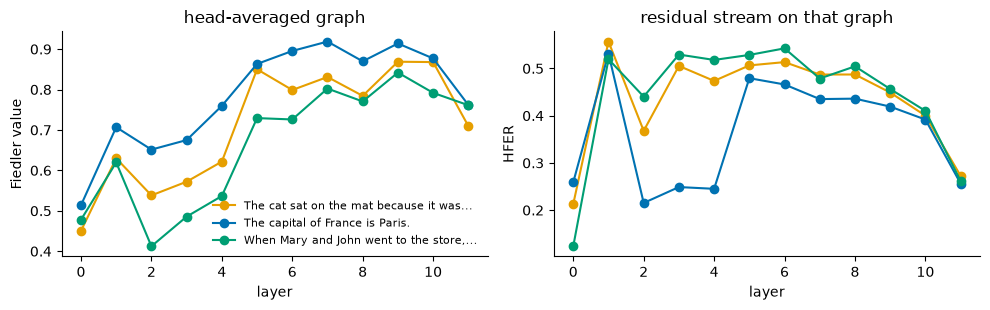

In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for i, (text, color) in enumerate(zip(texts, ["#E69F00", "#0072B2", "#009E73"])):
    label = text if len(text) < 40 else text[:37] + "..."
    axes[0].plot(cache.layers, cache.metric("graph.fiedler_value", text=i), marker="o", color=color, label=label)
    axes[1].plot(cache.layers, cache.metric("graph.hfer", text=i), marker="o", color=color)
axes[0].set(xlabel="layer", ylabel="Fiedler value", title="head-averaged graph")
axes[1].set(xlabel="layer", ylabel="HFER", title="residual stream on that graph")
axes[0].legend(fontsize=8, frameon=False)
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## Built-in views

Each view is self-contained SVG with tooltips (hover the cells, nodes, edges
and points in Jupyter or Colab), and `.save("view.html")` writes a page that
opens offline. `text=` picks a text of the batch.

In [6]:
cache.heatmap("fiedler_value", text=0)              # layers x heads

<heatmap view: Heatmap: attn.fiedler_value>

In [7]:
F = cat.metric("fiedler_value")                     # [layers, heads]
row, head = np.unravel_index(np.nanargmin(F), F.shape)
layer = cat.layers[row]
print(f"smallest Fiedler value: layer {layer}, head {head}, {F[row, head]:.4f}")
cat.graph(layer, head=int(head))                    # node colour: the Fiedler vector

smallest Fiedler value: layer 11, head 8, 0.0017


<graph view: Attention graph: layer 11, head 8>

In [8]:
cat.spectrum(layer, head=int(head))

<spectrum view: Spectrum: layer 11, head 8>

## A long table, and saving

`to_dataframe` gives one row per (text, layer, head, metric) with the
metric's family; `head` is missing for the head-averaged `graph` metrics.
`save` writes every array and the metadata to one `.npz` file.

In [9]:
df = cache.to_dataframe()
print(len(df), "rows")
df[df.metric == "graph.fiedler_value"].pivot(index="layer", columns="text_id", values="value").round(3)

4248 rows


text_id,0,1,2
layer,,,
0,0.450,0.514,0.478
1,0.630,0.707,0.620
2,0.538,0.651,0.412
3,0.572,0.675,0.486
4,0.622,0.760,0.537
5,0.850,0.863,0.729
6,0.799,0.895,0.726
7,0.831,0.919,0.802
8,0.784,0.870,0.771


In [10]:
path = cache.save("quickstart.npz")
again = st.SpectralCache.load(path)
print(again)
print("identical after reload:", np.array_equal(again["blocks.6.attn.fiedler_value"], fiedler))

SpectralCache('gpt2', 3 texts, 7-16 tokens, layers 0-11, 12 heads, metrics: attn=5, resid=4, graph=10)
identical after reload: True


## The same numbers from tensors you already have

`st.from_hf_outputs` measures a Hugging Face forward pass run with
`output_attentions=True`, with no second pass. `st.from_transformer_lens` and
`st.from_nnsight` do the same for a TransformerLens cache or an nnsight trace
(see the [TransformerLens and nnsight tutorial](https://vcnoel.github.io/spectral-trust/tutorials/interop/)).

In [11]:
ids = torch.tensor([model.tokenizer(texts[0])["input_ids"]])
with torch.no_grad():
    out = model.model(input_ids=ids, output_attentions=True, output_hidden_states=True)
from_hf = st.from_hf_outputs(out, model.model.config, ids, tokenizer=model.tokenizer)
diff = max(float(np.nanmax(np.abs(np.asarray(from_hf[k], float) - np.asarray(cat[k], float))))
           for k in cat.keys())
print(f"largest difference to run_with_spectra: {diff:.2e}")

largest difference to run_with_spectra: 0.00e+00


## Next

- [`02_animated_views.ipynb`](https://colab.research.google.com/github/vcnoel/spectral-trust/blob/main/notebooks/02_animated_views.ipynb): flow, waterfall and compare as pages, videos and GIFs.
- [`03_interventions.ipynb`](https://colab.research.google.com/github/vcnoel/spectral-trust/blob/main/notebooks/03_interventions.ipynb): the interventions of 0.5.0 on GPT-2 and IOI.
- [`04_phi3_prepositions.ipynb`](https://colab.research.google.com/github/vcnoel/spectral-trust/blob/main/notebooks/04_phi3_prepositions.ipynb): which words split Phi-3-mini's attention graph (T4 GPU).
- The documentation: [vcnoel.github.io/spectral-trust](https://vcnoel.github.io/spectral-trust/).